# Milestone 1 – Data-Engineering Questions

This notebook answers the three data-engineering questions of Milestone 1.

1. Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?
2. Do drivers podium more often at home, after controlling for starting position?
3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

Order of the notebook: load and light clean, then one section per question. Each question has a plan, the joins, the checks, a table, a plot, a justification (grain, missingness, pre-race cutoff) and a written answer.

The raw files in `data/raw` are only read, never written.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

## 0. Load and light clean

### 0.1 Load the tables we need

The three questions need 7 of the 14 tables. The notebook lives in `notebooks/`, so the raw folder is one level up.

In [2]:
RAW = '../data/raw/'

results = pd.read_csv(RAW + 'results.csv')
races = pd.read_csv(RAW + 'races.csv')
circuits = pd.read_csv(RAW + 'circuits.csv')
drivers = pd.read_csv(RAW + 'drivers.csv')
constructors = pd.read_csv(RAW + 'constructors.csv')
status = pd.read_csv(RAW + 'status.csv')
qualifying = pd.read_csv(RAW + 'qualifying.csv')

results.shape, races.shape, circuits.shape, drivers.shape, constructors.shape, status.shape, qualifying.shape

((26759, 18), (1125, 18), (77, 9), (861, 9), (212, 5), (139, 2), (10494, 9))

In [3]:
results.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


### 0.2 The `\N` sentinel

`position`, `time` and other columns show `\N`. That is text, so pandas reads the whole column as text. First we look at the types and count the `\N` cells.

In [4]:
results.dtypes

resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number                 str
grid                 int64
position               str
positionText           str
positionOrder        int64
points             float64
laps                 int64
time                   str
milliseconds           str
fastestLap             str
rank                   str
fastestLapTime         str
fastestLapSpeed        str
statusId             int64
dtype: object

In [5]:
# how many cells are the text \N, per column
(results == '\\N').sum()

resultId               0
raceId                 0
driverId               0
constructorId          0
number                 6
grid                   0
position           10953
positionText           0
positionOrder          0
points                 0
laps                   0
time               19079
milliseconds       19079
fastestLap         18507
rank               18249
fastestLapTime     18507
fastestLapSpeed    18507
statusId               0
dtype: int64

In [6]:
(qualifying == '\\N').sum()

qualifyId           0
raceId              0
driverId            0
constructorId       0
number              0
position            0
q1                156
q2               4625
q3               6819
dtype: int64

`position` should be a number but it is text, because 10,953 cells hold `\N`. The fix is to tell `read_csv` that `\N` means missing. We reload the tables that have it.

In [7]:
results = pd.read_csv(RAW + 'results.csv', na_values='\\N')
races = pd.read_csv(RAW + 'races.csv', na_values='\\N')
drivers = pd.read_csv(RAW + 'drivers.csv', na_values='\\N')
qualifying = pd.read_csv(RAW + 'qualifying.csv', na_values='\\N')
circuits = pd.read_csv(RAW + 'circuits.csv', na_values='\\N')

In [8]:
# check again: no \N left, and position is a number now
print((results == '\\N').sum().sum(), (qualifying == '\\N').sum().sum())
results.dtypes

0 0


resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number             float64
grid                 int64
position           float64
positionText           str
positionOrder        int64
points             float64
laps                 int64
time                   str
milliseconds       float64
fastestLap         float64
rank               float64
fastestLapTime         str
fastestLapSpeed    float64
statusId             int64
dtype: object

### 0.3 The second sentinel: empty strings in qualifying

`q2` and `q3` also have empty cells (`""`) that are not `\N`. We count them in the raw text of the file, then check what pandas did with them.

In [9]:
# count the empty quoted cells in the raw file text
raw_text = open(RAW + 'qualifying.csv').read()
raw_text.count('""')

68

In [10]:
qualifying[['q1', 'q2', 'q3']].isna().sum()

q1     156
q2    4647
q3    6865
dtype: int64

In [11]:
# is any empty string still in the table?
(qualifying[['q1', 'q2', 'q3']] == '').sum()

q1    0
q2    0
q3    0
dtype: int64

`read_csv` already turns an empty cell into a missing value, so no empty string is left. The missing counts above include both the `\N` cells and the empty cells. No extra fix is needed.

### 0.4 Dates

`races.date` is text. We need it as a real date to order the races in time.

In [12]:
races['date'].head(3)

0    2009-03-29
1    2009-04-05
2    2009-04-19
Name: date, dtype: str

In [13]:
races['date'] = pd.to_datetime(races['date'])
races['date'].head(3)

0   2009-03-29
1   2009-04-05
2   2009-04-19
Name: date, dtype: datetime64[us]

### 0.5 `raceId` is not in time order

We check if a bigger `raceId` always means a later race.

In [14]:
races.sort_values('raceId')[['raceId', 'year', 'round', 'date', 'name']].head(3)

,raceId,year,round,date,name
0,1,2009,1,2009-03-29,Australian Grand Prix
1,2,2009,2,2009-04-05,Malaysian Grand Prix
2,3,2009,3,2009-04-19,Chinese Grand Prix


In [15]:
# is the date always increasing when we sort by raceId?
races.sort_values('raceId')['date'].is_monotonic_increasing

False

`raceId` 1 is the first race of 2009, and the dates are not increasing with `raceId`. So for anything about time we use `year`, `round` and `date` from `races`, never `raceId`.

### 0.6 Whitespace in `drivers.nationality`

Question 2 matches the driver nationality to the circuit country, so the text must be exact. We check for spaces at the start or the end.

In [16]:
(drivers['nationality'] != drivers['nationality'].str.strip()).sum()

np.int64(1)

In [17]:
drivers['nationality'] = drivers['nationality'].str.strip()
(drivers['nationality'] != drivers['nationality'].str.strip()).sum()

np.int64(0)

### 0.7 Duplicate (raceId, driverId) rows in `results`

One row should be one driver in one race. We check if a driver appears more than once in the same race.

In [18]:
results.duplicated(['raceId', 'driverId']).sum()

np.int64(91)

In [19]:
# look at the duplicated pairs: which years are they from?
dup = results[results.duplicated(['raceId', 'driverId'], keep=False)]
dup = dup.merge(races[['raceId', 'year']], on='raceId')
print(dup[['raceId', 'driverId']].drop_duplicates().shape[0], 'pairs,', len(dup), 'rows')
dup['year'].value_counts().sort_index()

85 pairs, 176 rows


year
1950     8
1951     8
1952     6
1953    30
1954    33
1955    33
1956    24
1957    16
1958     6
1960     2
1961     4
1962     2
1964     2
1978     2
Name: count, dtype: int64

In [20]:
# a few examples: the same driver twice in the same race
dup.sort_values(['raceId', 'driverId']).head(4)[['raceId', 'year', 'driverId', 'constructorId', 'number', 'grid', 'positionText', 'positionOrder', 'laps']]

,raceId,year,driverId,constructorId,number,grid,positionText,positionOrder,laps
0,540,1978,229,54,10.0,0,F,26,0
1,540,1978,229,57,23.0,0,F,29,0
2,717,1964,373,172,1.0,1,7,7,102
175,717,1964,373,172,2.0,1,R,12,54


The duplicates are from 1950–1964 (shared drives: a driver took over a second car during the race) plus one pair in 1978.

**Rule: keep the row with the lowest `positionOrder`**, which is the best result of the driver in that race. Our questions ask "did this driver reach the podium in this race?", and a podium in the second car is still a podium for that driver.

All three questions use 2003 or later, except question 2, so this rule only touches question 2.

In [21]:
results = results.sort_values('positionOrder').drop_duplicates(['raceId', 'driverId'])
results.duplicated(['raceId', 'driverId']).sum(), len(results)

(np.int64(0), 26668)

### 0.8 What do `position`, `positionText`, `positionOrder` and `grid = 0` mean?

There are three "position" columns. We look at them before we use them.

In [22]:
# positionText values that are letters, not numbers
letters = results[~results['positionText'].str.isdigit()]
letters['positionText'].value_counts()

positionText
R    8819
F    1366
W     335
N     190
D     151
E       9
Name: count, dtype: int64

In [23]:
# position missing, positionText a letter, positionOrder missing
results['position'].isna().sum(), len(letters), results['positionOrder'].isna().sum()

(np.int64(10872), 10870, np.int64(0))

`position` is missing on 2 rows more than there are letters. We look at those 2 rows.

In [24]:
results[results['position'].isna() & results['positionText'].str.isdigit()][['raceId', 'driverId', 'grid', 'position', 'positionText', 'positionOrder', 'laps']]

,raceId,driverId,grid,position,positionText,positionOrder,laps
1148,71,18,8,NaN,11,11,56
1151,71,11,20,NaN,14,14,55


Two rows of one race have a number in `positionText` but no `position`. It is a small gap in the source. It does not matter for us, because we use `positionOrder`, which is never missing.

In [25]:
# which status goes with each letter (top 3 per letter)
letters = letters.merge(status, on='statusId')
letters.groupby('positionText')['status'].value_counts().groupby(level=0).head(3)

positionText  status            
D             Disqualified           147
              Accident                 1
              Collision                1
E             Excluded                 8
              Underweight              1
F             Did not qualify       1024
              Did not prequalify     330
              107% Rule                9
N             Not classified         171
              +8 Laps                  3
              +7 Laps                  3
R             Engine                1847
              Accident               948
              Collision              801
W             Withdrew               227
              Accident                29
              Engine                  19
Name: count, dtype: int64

Now `grid`. A grid position of 0 cannot be a real slot, so we look at who has it.

In [26]:
grid0 = results[results['grid'] == 0].merge(races[['raceId', 'year']], on='raceId')
len(grid0)

1635

In [27]:
grid0['positionText'].str.isdigit().map({True: 'classified (number)', False: 'letter'}).value_counts(), grid0[~grid0['positionText'].str.isdigit()]['positionText'].value_counts()

(positionText
 letter                 1575
 classified (number)      60
 Name: count, dtype: int64,
 positionText
 F    1346
 W     202
 R      14
 E       7
 D       6
 Name: count, dtype: int64)

In [28]:
# grid 0 rows where the driver did race laps: how many, from which year, any podium?
raced = grid0[grid0['laps'] > 0]
len(raced), raced['year'].min(), raced['year'].max(), (grid0['positionOrder'] <= 3).sum()

(72, np.int64(2015), np.int64(2024), np.int64(0))

**What we found, and what the documentation says**

We looked the columns up, because this dataset is a dump of the Ergast F1 database.

- **`positionText` codes.** The FastF1 documentation (it wraps the Ergast API, field `ClassifiedPosition`) lists them: a number if the driver is classified, else `R` = retired, `D` = disqualified, `E` = excluded, `W` = withdrawn, `F` = failed to qualify, `N` = not classified. Our status table above agrees with that (`F` goes with "Did not qualify", `W` with "Withdrew", `D` with "Disqualified").
- **`position`** is the official finishing position and is missing when `positionText` is a letter (plus the 2 rows above). **`positionOrder`** is never missing: it is a rank of all rows of a race, so retired drivers also get a number. That is why the assignment defines the podium as `positionOrder <= 3`.
- **`grid`.** The Jolpica-F1 documentation (the maintained copy of the Ergast API) describes `grid` only as "the driver's grid position". The original Ergast site is offline, so we could not open the page that explains `grid = 0`. We therefore read it from the data above: most `grid = 0` rows are drivers who never started (`F` and `W`), and a small group (72 rows, all from 2015 onward) did race laps. These are pit-lane starts: the car raced but had no slot on the grid. No `grid = 0` row is a podium.
- **`qualifying.position` vs `results.grid`.** The Ergast documentation says qualifying results are only fully supported from the 2003 season onwards. `qualifying.position` is the result of the qualifying session, `grid` is the slot where the car really started after penalties. The Jolpica documentation gives an example of a driver who qualified 13th and started 18th.

So for the rest of the notebook: a driver **started** the race if `positionText` is not `F` and not `W`, and `grid = 0` is "no grid slot", never "better than pole".

In [29]:
results['started'] = ~results['positionText'].isin(['F', 'W'])
results['started'].value_counts()

started
True     24967
False     1701
Name: count, dtype: int64

### 0.9 The base table: results + races + circuits

Every question needs the year and the circuit of each result. `results` has neither. So we join `results → races` on `raceId`, then `races → circuits` on `circuitId`. We check that the join does not add or lose rows.

In [30]:
races_small = races[['raceId', 'year', 'round', 'date', 'circuitId', 'name']].rename(columns={'name': 'race_name'})
circuits_small = circuits[['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'})

merged = results.merge(races_small, on='raceId').merge(circuits_small, on='circuitId')
len(results), len(merged)

(26668, 26668)

In [31]:
merged['podium'] = (merged['positionOrder'] <= 3).astype(int)
merged[['raceId', 'year', 'race_name', 'circuit', 'country', 'driverId', 'grid', 'positionText', 'positionOrder', 'podium']].head()

,raceId,year,race_name,circuit,country,driverId,grid,positionText,positionOrder,podium
0,500,1980,South African Grand Prix,Kyalami,South Africa,163,2,1,1,1
1,809,1953,Indianapolis 500,Indianapolis Motor Speedway,USA,657,1,1,1,1
2,20,2008,Bahrain Grand Prix,Bahrain International Circuit,Bahrain,13,2,1,1,1
3,1144,2024,Abu Dhabi Grand Prix,Yas Marina Circuit,UAE,846,1,1,1,1
4,405,1986,Spanish Grand Prix,Circuito de Jerez,Spain,102,1,1,1,1


One more check on the target: a race should have 3 podium rows. In the 1950s two drivers could share one car and both get the same position, so some races have more.

In [32]:
per_race = merged.groupby(['raceId', 'year'])['podium'].sum().reset_index()
per_race['podium'].value_counts().sort_index()

podium
3    1107
4      16
5       2
Name: count, dtype: int64

In [33]:
# the races with more than 3 podium rows are all old
per_race[per_race['podium'] > 3]['year'].agg(['min', 'max', 'count'])

min      1950
max      1960
count      18
Name: year, dtype: int64

The races with more than 3 podium rows end in the early 1960s. They are real shared podiums, so we keep them. Questions 1 and 3 use 2003 onward and are not affected.

---
## Question 1 – Which circuits convert a front-row start into a podium most often, and does the ranking change after 2014?

### Plan

- **Unit (grain):** one front-row starter in one race.
- **Conversion rate of a circuit** = podiums of its front-row starters / number of its front-row starters.
- **Two definitions of "front row"**, because they can differ after penalties:
  - by **grid**: `results.grid` is 1 or 2 (where the car really started);
  - by **qualifying**: `qualifying.position` is 1 or 2 (the result of the session, before penalties).
- **Joins (multi-hop):** `results → races` (`raceId`) gives the year, `races → circuits` (`circuitId`) gives the circuit, `results → qualifying` (`raceId`, `driverId`) gives the qualifying position.
- **Eras:** before the hybrid era vs. 2014 onward.

### 1.1 Which years can we use? Qualifying coverage

Before choosing the years we check how many result rows have a matching qualifying row in each season.

In [34]:
has_quali = merged.merge(qualifying[['raceId', 'driverId', 'qualifyId']], on=['raceId', 'driverId'], how='left')
coverage = has_quali.groupby('year')['qualifyId'].apply(lambda s: s.notna().mean())
coverage[coverage.index >= 1992]

year
1992    0.000000
1993    0.000000
1994    0.882883
1995    1.000000
1996    0.435294
1997    0.585106
1998    0.438395
1999    0.184659
2000    0.235925
2001    0.058824
2002    0.116022
2003    1.000000
2004    1.000000
2005    1.000000
2006    1.000000
2007    1.000000
2008    1.000000
2009    1.000000
2010    1.000000
2011    0.991228
2012    0.991667
2013    1.000000
2014    0.995086
2015    0.989418
2016    0.989177
2017    0.995000
2018    1.000000
2019    0.995238
2020    1.000000
2021    0.997727
2022    1.000000
2023    1.000000
2024    1.000000
Name: qualifyId, dtype: float64

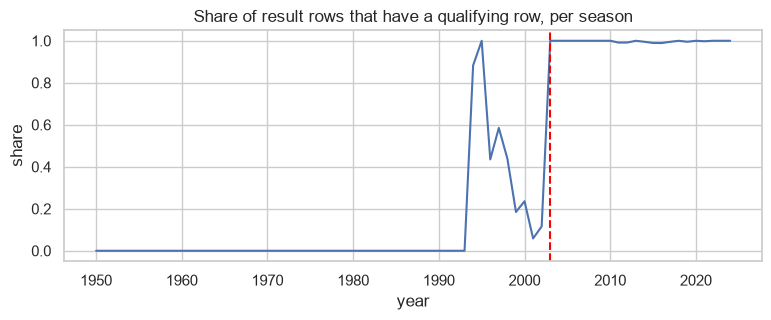

In [35]:
coverage.plot(figsize=(9, 3))
plt.axvline(2003, color='red', linestyle='--')
plt.title('Share of result rows that have a qualifying row, per season')
plt.ylabel('share')
plt.show()

There is no qualifying data before 1994, 1996–2002 is mostly missing, and from 2003 it is complete. This matches the Ergast note that qualifying is fully supported from 2003.

**Decision: use 2003–2024.** We need both definitions on the same races to compare them, and the qualifying definition only exists from 2003. This gives two eras of 11 seasons each: **2003–2013** and **2014–2024**.

### 1.2 Build the table for question 1

We keep 2003 onward and only drivers who started the race (a "front-row start" needs a start). Then we left-join qualifying, so a result without a qualifying row is kept with a missing value.

In [36]:
q1 = merged[merged['year'] >= 2003]
print(len(q1), 'rows from 2003')
q1 = q1[q1['started']]
print(len(q1), 'rows after dropping drivers who did not start')

8970 rows from 2003
8910 rows after dropping drivers who did not start


In [37]:
quali_small = qualifying[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})
before = len(q1)
q1 = q1.merge(quali_small, on=['raceId', 'driverId'], how='left')
before, len(q1), q1['quali_pos'].isna().sum()

(8910, 8910, np.int64(21))

In [38]:
q1['era'] = '2003-2013'
q1.loc[q1['year'] >= 2014, 'era'] = '2014-2024'
q1.groupby('era')['raceId'].nunique()

era
2003-2013    200
2014-2024    228
Name: raceId, dtype: int64

### 1.3 How often is qualifying position different from grid?

This is the reason the question asks for two definitions.

In [39]:
matched = q1[q1['quali_pos'].notna()]
(matched['quali_pos'] != matched['grid']).mean()

np.float64(0.2765215434807065)

In [40]:
q1['front_grid'] = q1['grid'].isin([1, 2])
q1['front_quali'] = q1['quali_pos'] <= 2
pd.crosstab(q1['front_quali'], q1['front_grid'])

front_grid,False,True
front_quali,,
False,8022,36
True,37,815


In [41]:
# drivers who qualified in the top 2 but did not start on the front row: where did they start?
q1[q1['front_quali'] & ~q1['front_grid']]['grid'].value_counts().sort_index()

grid
0     1
3     1
4     3
5     6
6     5
7     6
8     1
10    1
11    3
12    5
13    1
14    1
19    1
20    1
24    1
Name: count, dtype: int64

In [42]:
# how many front-row starters does each race have, by each definition? (we expect 2)
print(q1.groupby('raceId')['front_grid'].sum().value_counts())
print(q1.groupby('raceId')['front_quali'].sum().value_counts())

front_grid
2    424
1      3
0      1
Name: count, dtype: int64
front_quali
2    425
1      2
0      1
Name: count, dtype: int64


Almost every race has 2. One race has no front-row starter at all, so we look at it in the base table (before the "started" filter).

In [43]:
per_race_front = q1.groupby('raceId')['front_grid'].sum()
empty_race = per_race_front[per_race_front == 0].index
merged[merged['raceId'].isin(empty_race)].sort_values('grid')[['year', 'race_name', 'grid', 'positionText', 'laps']].head(6)

,year,race_name,grid,positionText,laps
7858,2005,United States Grand Prix,1,W,0
8045,2005,United States Grand Prix,2,W,0
10060,2005,United States Grand Prix,3,W,0
10787,2005,United States Grand Prix,4,W,0
1020,2005,United States Grand Prix,5,1,73
11801,2005,United States Grand Prix,6,W,0


Qualifying position and grid differ on a large share of all rows, but for the front row they agree most of the time. The crosstab shows the few dozen cases where a top-2 qualifier lost the front row (penalty, pit-lane start = grid 0) and someone else took the slot.

The race with no front-row starter is the 2005 United States Grand Prix: the cars on grid 1 to 4 withdrew before the start (`W`), so nobody started from the front row. A few other races have only one front-row starter for the same reason (the car did not start, so we dropped it) or because the qualifying row is missing.

### 1.4 Overall conversion rate, by definition and era

First the big picture, before we split by circuit.

In [44]:
overall_grid = q1[q1['front_grid']].groupby('era')['podium'].agg(['size', 'sum', 'mean'])
overall_quali = q1[q1['front_quali']].groupby('era')['podium'].agg(['size', 'sum', 'mean'])
overall = overall_grid.join(overall_quali, lsuffix='_grid', rsuffix='_quali')
overall

,size_grid,sum_grid,mean_grid,size_quali,sum_quali,mean_quali
era,,,,,,
2003-2013,398,272,0.683417,398,269,0.675879
2014-2024,453,345,0.761589,454,336,0.740088


### 1.5 Conversion rate per circuit and era (grid definition)

Group the front-row starters by circuit and era. `races` is the number of races, `starts` the number of front-row starters, `rate` = podiums / starts.

In [45]:
by_grid = q1[q1['front_grid']].groupby(['circuit', 'era']).agg(races=('raceId', 'nunique'), starts=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
by_grid['rate'] = by_grid['podiums'] / by_grid['starts']
by_grid.head()

,circuit,era,races,starts,podiums,rate
0,Albert Park Grand Prix Circuit,2003-2013,11,22,13,0.590909
1,Albert Park Grand Prix Circuit,2014-2024,9,18,13,0.722222
2,Autodromo Enzo e Dino Ferrari,2003-2013,4,8,5,0.625000
3,Autodromo Enzo e Dino Ferrari,2014-2024,4,8,6,0.750000
4,Autodromo Internazionale del Mugello,2014-2024,1,2,2,1.000000


A circuit with one or two races would give 100% or 0% by luck. So we look at how many races each circuit has per era before we choose a minimum.

In [46]:
by_grid.groupby('era')['races'].describe()

,count,mean,std,min,25%,50%,75%,max
era,,,,,,,,
2003-2013,27.0,7.37037,3.364385,1.0,4.5,8.0,11.00,11.0
2014-2024,32.0,7.12500,3.799406,1.0,4.0,8.5,10.25,13.0


In [47]:
by_grid.pivot(index='circuit', columns='era', values='races').fillna(0).astype(int).sort_values('2014-2024', ascending=False)

era,2003-2013,2014-2024
circuit,,
Red Bull Ring,1,13
Bahrain International Circuit,9,12
Silverstone Circuit,11,12
Circuit de Barcelona-Catalunya,11,11
Autodromo Nazionale di Monza,11,11
Hungaroring,11,11
Circuit de Spa-Francorchamps,9,11
Yas Marina Circuit,5,11
Autódromo José Carlos Pace,11,10


**Minimum: at least 5 races in the era** (about 10 front-row starts). With fewer races one result moves the rate by more than 10 points. A higher minimum would remove most of the newer circuits.

In [48]:
MIN_RACES = 5
by_grid_ok = by_grid[by_grid['races'] >= MIN_RACES]
by_grid_ok.groupby('era')['circuit'].count()

era
2003-2013    20
2014-2024    19
Name: circuit, dtype: int64

In [49]:
# top 10 circuits, 2003-2013
by_grid_ok[by_grid_ok['era'] == '2003-2013'].sort_values(['rate', 'starts'], ascending=False).head(10)

,circuit,era,races,starts,podiums,rate
23,Circuit de Nevers Magny-Cours,2003-2013,6,12,11,0.916667
34,Istanbul Park,2003-2013,7,14,11,0.785714
5,Autodromo Nazionale di Monza,2003-2013,11,22,17,0.772727
21,Circuit de Monaco,2003-2013,11,22,17,0.772727
51,Silverstone Circuit,2003-2013,11,22,16,0.727273
24,Circuit de Spa-Francorchamps,2003-2013,9,18,13,0.722222
54,Suzuka Circuit,2003-2013,9,18,13,0.722222
29,Hockenheimring,2003-2013,7,14,10,0.714286
19,Circuit de Barcelona-Catalunya,2003-2013,11,22,15,0.681818
11,Bahrain International Circuit,2003-2013,9,18,12,0.666667


In [50]:
# top 10 circuits, 2014-2024
by_grid_ok[by_grid_ok['era'] == '2014-2024'].sort_values(['rate', 'starts'], ascending=False).head(10)

,circuit,era,races,starts,podiums,rate
22,Circuit de Monaco,2014-2024,10,19,17,0.894737
55,Suzuka Circuit,2014-2024,9,18,16,0.888889
58,Yas Marina Circuit,2014-2024,11,22,19,0.863636
20,Circuit de Barcelona-Catalunya,2014-2024,11,22,18,0.818182
25,Circuit de Spa-Francorchamps,2014-2024,11,22,18,0.818182
53,Sochi Autodrom,2014-2024,8,16,13,0.812500
27,Circuit of the Americas,2014-2024,10,20,16,0.800000
10,Autódromo José Carlos Pace,2014-2024,10,19,15,0.789474
50,Shanghai International Circuit,2014-2024,7,14,11,0.785714
16,Circuit Gilles Villeneuve,2014-2024,9,18,14,0.777778


### 1.6 Does the ranking change? Circuits with enough races in both eras

To compare ranks we need the same circuits in both eras. We keep the circuits that pass the minimum in both.

In [51]:
rate_grid = by_grid_ok.pivot(index='circuit', columns='era', values='rate').dropna()
rate_grid['change'] = rate_grid['2014-2024'] - rate_grid['2003-2013']
# method='first': circuits with the same rate get neighbouring ranks, so the plot labels do not overlap
rate_grid['rank_before'] = rate_grid['2003-2013'].rank(ascending=False, method='first').astype(int)
rate_grid['rank_after'] = rate_grid['2014-2024'].rank(ascending=False, method='first').astype(int)
rate_grid['rank_move'] = rate_grid['rank_before'] - rate_grid['rank_after']
rate_grid = rate_grid.sort_values('2014-2024', ascending=False)
rate_grid.round(3)

era,2003-2013,2014-2024,change,rank_before,rank_after,rank_move
circuit,,,,,,
Circuit de Monaco,0.773,0.895,0.122,2,1,1
Suzuka Circuit,0.722,0.889,0.167,5,2,3
Yas Marina Circuit,0.600,0.864,0.264,11,3,8
Circuit de Spa-Francorchamps,0.722,0.818,0.096,4,5,-1
Circuit de Barcelona-Catalunya,0.682,0.818,0.136,6,4,2
Autódromo José Carlos Pace,0.591,0.789,0.199,13,6,7
Shanghai International Circuit,0.650,0.786,0.136,8,7,1
Circuit Gilles Villeneuve,0.600,0.778,0.178,10,8,2
Silverstone Circuit,0.727,0.750,0.023,3,9,-6


In [52]:
# do the two eras agree on the order? 1 = same ranking, 0 = no relation
rate_grid['2003-2013'].corr(rate_grid['2014-2024'], method='spearman')

np.float64(0.3561955619958441)

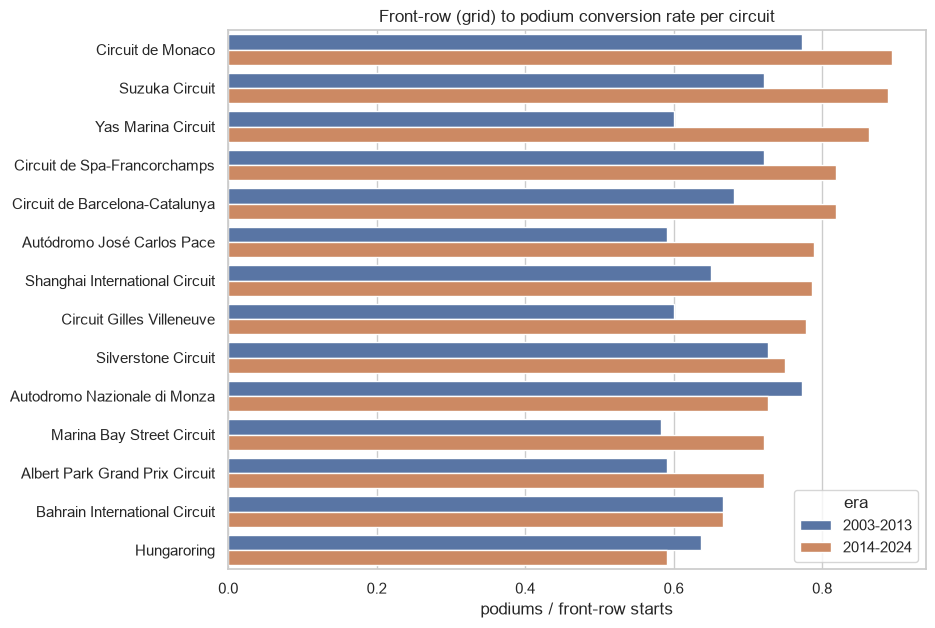

In [53]:
both = by_grid_ok[by_grid_ok['circuit'].isin(rate_grid.index)]

plt.figure(figsize=(9, 7))
sns.barplot(data=both, y='circuit', x='rate', hue='era', order=rate_grid.index)
plt.title('Front-row (grid) to podium conversion rate per circuit')
plt.xlabel('podiums / front-row starts')
plt.ylabel('')
plt.show()

The same data as ranks: one line per circuit, from its rank in 2003–2013 to its rank in 2014–2024. Crossing lines mean the ranking changed. Circuits with exactly the same rate get neighbouring ranks.

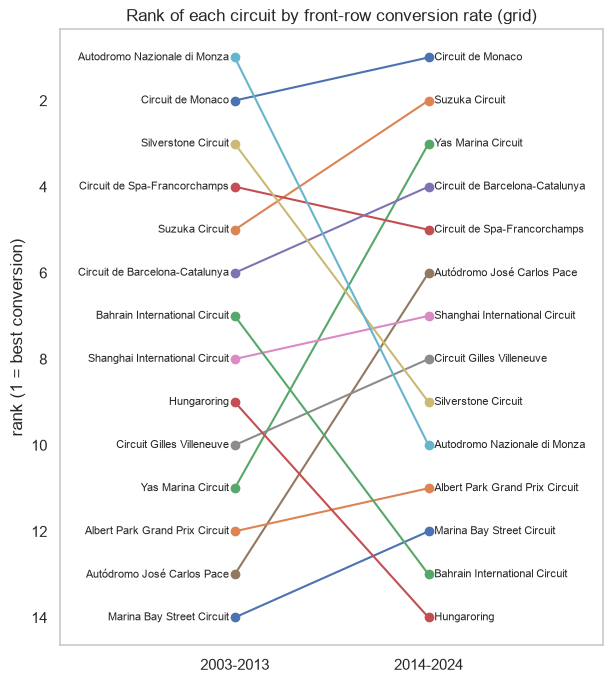

In [54]:
plt.figure(figsize=(7, 8))
for circuit, row in rate_grid.iterrows():
    plt.plot([0, 1], [row['rank_before'], row['rank_after']], marker='o')
    plt.text(-0.03, row['rank_before'], circuit, ha='right', va='center', fontsize=8)
    plt.text(1.03, row['rank_after'], circuit, ha='left', va='center', fontsize=8)
plt.xticks([0, 1], ['2003-2013', '2014-2024'])
plt.xlim(-0.9, 1.9)
plt.gca().invert_yaxis()
plt.ylabel('rank (1 = best conversion)')
plt.title('Rank of each circuit by front-row conversion rate (grid)')
plt.grid(False)
plt.show()

### 1.7 The same with the qualifying definition

Now "front row" means qualifying position 1 or 2, even if a penalty moved the driver back on the grid.

In [55]:
by_quali = q1[q1['front_quali']].groupby(['circuit', 'era']).agg(races=('raceId', 'nunique'), starts=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
by_quali['rate'] = by_quali['podiums'] / by_quali['starts']
by_quali_ok = by_quali[by_quali['races'] >= MIN_RACES]
rate_quali = by_quali_ok.pivot(index='circuit', columns='era', values='rate').dropna()
rate_quali.sort_values('2014-2024', ascending=False).round(3)

era,2003-2013,2014-2024
circuit,,
Circuit de Monaco,0.682,0.895
Suzuka Circuit,0.722,0.889
Circuit de Spa-Francorchamps,0.722,0.818
Yas Marina Circuit,0.600,0.818
Circuit de Barcelona-Catalunya,0.636,0.818
Shanghai International Circuit,0.700,0.786
Silverstone Circuit,0.773,0.750
Autodromo Nazionale di Monza,0.727,0.727
Circuit Gilles Villeneuve,0.600,0.722


In [56]:
# grid definition next to qualifying definition, same circuits
compare = rate_grid[['2003-2013', '2014-2024']].join(rate_quali, lsuffix=' grid', rsuffix=' quali')
compare['diff 2003-2013'] = compare['2003-2013 quali'] - compare['2003-2013 grid']
compare['diff 2014-2024'] = compare['2014-2024 quali'] - compare['2014-2024 grid']
compare.round(3)

era,2003-2013 grid,2014-2024 grid,2003-2013 quali,2014-2024 quali,diff 2003-2013,diff 2014-2024
circuit,,,,,,
Circuit de Monaco,0.773,0.895,0.682,0.895,-0.091,0.000
Suzuka Circuit,0.722,0.889,0.722,0.889,0.000,0.000
Yas Marina Circuit,0.600,0.864,0.600,0.818,0.000,-0.045
Circuit de Spa-Francorchamps,0.722,0.818,0.722,0.818,0.000,0.000
Circuit de Barcelona-Catalunya,0.682,0.818,0.636,0.818,-0.045,0.000
Autódromo José Carlos Pace,0.591,0.789,0.591,0.684,0.000,-0.105
Shanghai International Circuit,0.650,0.786,0.700,0.786,0.050,0.000
Circuit Gilles Villeneuve,0.600,0.778,0.600,0.722,0.000,-0.056
Silverstone Circuit,0.727,0.750,0.773,0.750,0.045,0.000


In [57]:
# how similar are the two definitions? rank correlation per era
compare['2003-2013 grid'].corr(compare['2003-2013 quali'], method='spearman'), compare['2014-2024 grid'].corr(compare['2014-2024 quali'], method='spearman')

(np.float64(0.8866688559751867), np.float64(0.8777972846008472))

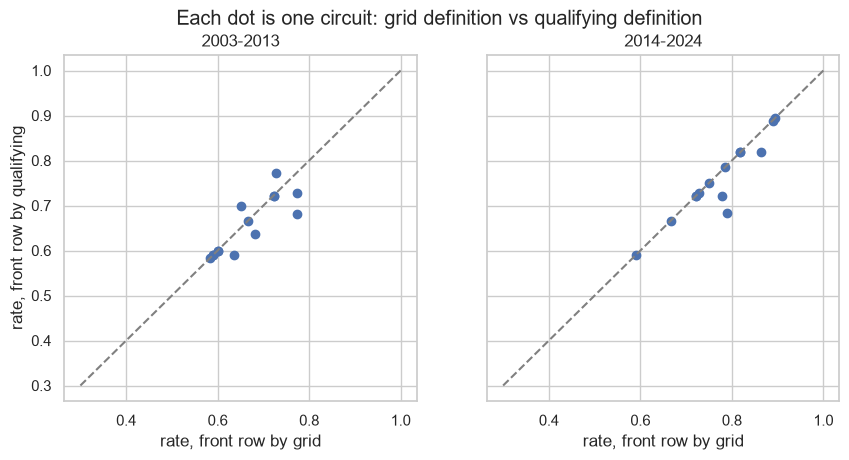

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, era in zip(axes, ['2003-2013', '2014-2024']):
    ax.scatter(compare[era + ' grid'], compare[era + ' quali'])
    ax.plot([0.3, 1], [0.3, 1], color='grey', linestyle='--')
    ax.set_title(era)
    ax.set_xlabel('rate, front row by grid')
axes[0].set_ylabel('rate, front row by qualifying')
plt.suptitle('Each dot is one circuit: grid definition vs qualifying definition')
plt.show()

### 1.8 Justification: grain, missingness, pre-race cutoff

**Grain.** One row is one driver who started one race from the front row. It comes from the base table, which is unique on (`raceId`, `driverId`) after the duplicate rule. The joins to `races`, `circuits` and `qualifying` did not change the row count (checked above), so no front-row start is counted twice. A circuit gets about 2 rows per race.

**Missingness.**
- Qualifying data is missing before 1994 and mostly missing in 1996–2002, so we use 2003–2024 only. This is the reason for the year range.
- Inside 2003–2024, 21 starters have no qualifying row. They stay in the table (left join) and simply cannot be "front row by qualifying".
- `grid = 0` is not a position. It never passes the `grid` 1-or-2 test, so pit-lane starters are not counted as front row.
- Drivers who did not start (`W`) are dropped: 60 rows. Because of that, 1 race has no front-row starter and 3 have one.
- Circuits with fewer than 5 races in an era are not ranked in that era. The ranking comparison uses the 14 circuits that have at least 5 races in both eras.

**Pre-race cutoff.** Both front-row flags are known before the race: qualifying position after the session, grid when the starting grid is published. The podium is the outcome, known after the race. So "front row" is a legal pre-race feature and the conversion rate is a description of past races. If a circuit's rate is used as a feature later, it must be computed from earlier races only.

### 1.9 Answer to question 1

**Overall.** A front-row start became a podium in **68.3%** of cases in 2003–2013 (272 of 398) and in **76.2%** in 2014–2024 (345 of 453). So in the hybrid era the front row is worth more almost everywhere.

**Which circuits convert most often (front row by grid, at least 5 races in the era).**

| 2003–2013 | rate | 2014–2024 | rate |
|---|---|---|---|
| Magny-Cours | 91.7% (11/12) | Monaco | 89.5% (17/19) |
| Istanbul Park | 78.6% (11/14) | Suzuka | 88.9% (16/18) |
| Monza | 77.3% (17/22) | Yas Marina | 86.4% (19/22) |
| Monaco | 77.3% (17/22) | Barcelona-Catalunya | 81.8% (18/22) |
| Silverstone | 72.7% (16/22) | Spa-Francorchamps | 81.8% (18/22) |

**Does the ranking change after 2014?** Yes, quite a lot. For the 14 circuits with at least 5 races in both eras, the rank correlation between the two eras is only 0.36 (1 would mean the same order).
- Monaco stays at the top (77.3% → 89.5%) and Spa and Suzuka stay near the top.
- Big climbers: Yas Marina (60.0% → 86.4%) and Interlagos (59.1% → 78.9%).
- Big fallers: Monza (77.3% → 72.7%, from the top to 10th of 14), Silverstone (72.7% → 75.0%, 3rd to 9th, because the others rose more), Bahrain (66.7% → 66.7%) and the Hungaroring (63.6% → 59.1%, now last).
- 11 of the 14 circuits have a higher rate in the hybrid era, 1 is equal and 2 are lower.

**Qualifying position vs grid.** The two differ on 27.7% of all driver rows from 2003, but the front row is more stable: of 852 top-2 qualifiers, 815 also started on the front row and 37 (4.3%) did not, mostly because of a grid penalty. With the qualifying definition the overall rates are a little lower (67.6% and 74.0%), because a top-2 qualifier who is moved back has a harder race. The circuit ranking is nearly the same with both definitions (rank correlation 0.89 and 0.88). The largest gaps are Monaco in 2003–2013 (77.3% by grid, 68.2% by qualifying) and Interlagos in 2014–2024 (78.9% by grid, 68.4% by qualifying).

**How sure are we?** Not very, for single circuits. Each rate is built on only 10 to 22 front-row starts, so one podium more or less moves it by 5 to 10 points. The overall rise from 68% to 76% is solid. The exact order of circuits next to each other is not, and part of the ranking change is just noise.

---
## Question 2 – Do drivers podium more often at home, after controlling for starting position?

### Plan

- **Unit (grain):** one driver starting one race.
- **Home race:** the country of the circuit is the country of the driver's nationality.
- **Joins (multi-hop):** `results → races` (`raceId`) `→ circuits` (`circuitId`) gives the circuit country, and `results → drivers` (`driverId`) gives the nationality. Neither is in `results`.
- **Control for starting position:** compare home and away drivers inside the same grid group, then combine the groups into one number.

### 2.1 The two columns do not match as they are

The driver has a demonym (`British`), the circuit has a country name (`UK`). We look at both lists.

In [59]:
drivers['nationality'].value_counts()

nationality
British              166
American             158
Italian               99
French                73
German                50
Brazilian             32
Argentine             24
Swiss                 23
Belgian               23
South African         23
Japanese              20
Australian            19
Dutch                 18
Spanish               15
Austrian              15
Canadian              14
Swedish               10
New Zealander         10
Finnish                9
Mexican                6
Irish                  5
Danish                 5
Portuguese             4
Monegasque             4
Rhodesian              4
Uruguayan              4
Russian                4
Colombian              3
Venezuelan             3
East German            3
Indian                 2
Thai                   2
Polish                 1
Hungarian              1
Czech                  1
Malaysian              1
Chilean                1
Liechtensteiner        1
American-Italian       1
Argentine-Ita

In [60]:
circuits['country'].value_counts()

country
USA              11
France            7
Spain             6
UK                4
Italy             4
Portugal          4
Canada            3
Germany           3
Belgium           3
Japan             3
Australia         2
Brazil            2
South Africa      2
Austria           2
Malaysia          1
Bahrain           1
Turkey            1
Monaco            1
Hungary           1
Singapore         1
China             1
United States     1
UAE               1
Argentina         1
Mexico            1
Korea             1
Netherlands       1
Sweden            1
Morocco           1
Switzerland       1
India             1
Russia            1
Azerbaijan        1
Saudi Arabia      1
Qatar             1
Name: count, dtype: int64

Two things to fix. First, `circuits.country` has both `USA` and `United States` for the same country. We make them one value in our merged table.

In [61]:
merged[merged['country'].isin(['USA', 'United States'])].groupby('country')['circuit'].unique()

country
USA              [Indianapolis Motor Speedway, Circuit of the A...
United States                     [Las Vegas Strip Street Circuit]
Name: circuit, dtype: object

In [62]:
merged['country'] = merged['country'].replace('United States', 'USA')
merged[merged['country'].isin(['USA', 'United States'])]['country'].value_counts()

country
USA    2025
Name: count, dtype: int64

Second, we need a mapping from nationality to country. It is a plain dictionary so every choice is visible. Notes on the unclear ones:

- `Argentine` and `Argentinian` are the same nationality written two ways → `Argentina`.
- `American-Italian` and `Argentine-Italian` (one driver each) → the first nationality.
- `East German` → `Germany` (the German Grand Prix was in West Germany, but it is the closest home race).
- `Monegasque` → `Monaco`.
- `Rhodesian`, `Liechtensteiner` and a few others are mapped to their country, but no race was ever held there, so these drivers have no home race.

In [63]:
nat_to_country = {
    'British': 'UK', 'American': 'USA', 'Italian': 'Italy', 'French': 'France', 'German': 'Germany',
    'Brazilian': 'Brazil', 'Argentine': 'Argentina', 'Argentinian': 'Argentina', 'Swiss': 'Switzerland',
    'Belgian': 'Belgium', 'South African': 'South Africa', 'Japanese': 'Japan', 'Australian': 'Australia',
    'Dutch': 'Netherlands', 'Spanish': 'Spain', 'Austrian': 'Austria', 'Canadian': 'Canada',
    'Swedish': 'Sweden', 'New Zealander': 'New Zealand', 'Finnish': 'Finland', 'Mexican': 'Mexico',
    'Irish': 'Ireland', 'Danish': 'Denmark', 'Portuguese': 'Portugal', 'Monegasque': 'Monaco',
    'Rhodesian': 'Rhodesia', 'Uruguayan': 'Uruguay', 'Russian': 'Russia', 'Colombian': 'Colombia',
    'Venezuelan': 'Venezuela', 'East German': 'Germany', 'Indian': 'India', 'Thai': 'Thailand',
    'Polish': 'Poland', 'Hungarian': 'Hungary', 'Czech': 'Czech Republic', 'Malaysian': 'Malaysia',
    'Chilean': 'Chile', 'Liechtensteiner': 'Liechtenstein', 'American-Italian': 'USA',
    'Argentine-Italian': 'Argentina', 'Indonesian': 'Indonesia', 'Chinese': 'China',
}
drivers['home_country'] = drivers['nationality'].map(nat_to_country)
drivers['home_country'].isna().sum()

np.int64(0)

Every nationality got a country. Now we check which of these countries never held a race in our data. Drivers from there can never be "at home".

In [64]:
race_countries = merged['country'].unique()
no_home = drivers[~drivers['home_country'].isin(race_countries)]
no_home.groupby(['nationality', 'home_country'])['driverId'].count()

nationality      home_country  
Chilean          Chile              1
Colombian        Colombia           3
Czech            Czech Republic     1
Danish           Denmark            5
Finnish          Finland            9
Indonesian       Indonesia          1
Irish            Ireland            5
Liechtensteiner  Liechtenstein      1
New Zealander    New Zealand       10
Polish           Poland             1
Rhodesian        Rhodesia           4
Thai             Thailand           2
Uruguayan        Uruguay            4
Venezuelan       Venezuela          3
Name: driverId, dtype: int64

### 2.2 Build the table for question 2

Join the nationality onto the base table, then mark the home races.

In [65]:
before = len(merged)
q2 = merged.merge(drivers[['driverId', 'nationality', 'home_country']], on='driverId')
q2['home'] = (q2['home_country'] == q2['country']).astype(int)
before, len(q2), q2['home'].sum()

(26668, 26668, np.int64(2491))

Now three filters. We look at each one before we apply it.

**Filter 1: the Indianapolis 500.** It counted for the championship in 1950–1960 but almost only American drivers who did not race elsewhere took part. All of them are "at home", and they are a different group from the normal F1 field.

In [66]:
indy = q2[q2['race_name'] == 'Indianapolis 500']
indy['year'].nunique(), len(indy), indy['home'].mean()

(11, 381, np.float64(0.9973753280839895))

In [67]:
# how many Indy 500 drivers ever raced in another race?
indy_drivers = indy['driverId'].unique()
others = q2[(q2['race_name'] != 'Indianapolis 500') & q2['driverId'].isin(indy_drivers)]['driverId'].nunique()
len(indy_drivers), others

(107, 4)

In [68]:
q2 = q2[q2['race_name'] != 'Indianapolis 500']
len(q2)

26287

**Filter 2: drivers who did not start, and starts without a grid slot.** The question controls for starting position, so we need a real grid position. Drivers with `F` or `W` never started. The pit-lane starts (`grid = 0` but raced) have no grid position to compare.

In [69]:
print((~q2['started']).sum(), 'did not start')
print((q2['started'] & (q2['grid'] == 0)).sum(), 'started with grid 0')

1701 did not start
87 started with grid 0


In [70]:
q2 = q2[q2['started'] & (q2['grid'] > 0)]
len(q2), q2['grid'].min(), q2['grid'].max()

(24499, np.int64(1), np.int64(34))

**Filter 3: drivers whose country never held a race.** They are always "away". If we keep them, the away group contains a kind of driver that the home group cannot contain. So we keep only drivers who have at least one possible home race.

In [71]:
has_home = q2['home_country'].isin(race_countries)
(~has_home).sum(), q2[~has_home]['driverId'].nunique()

(np.int64(2324), 43)

In [72]:
q2 = q2[has_home]
q2['home'].value_counts()

home
0    20248
1     1927
Name: count, dtype: int64

### 2.3 The raw comparison (no control yet)

In [73]:
raw = q2.groupby('home').agg(starts=('podium', 'size'), podiums=('podium', 'sum'), podium_rate=('podium', 'mean'), mean_grid=('grid', 'mean'), median_grid=('grid', 'median'))
raw

,starts,podiums,podium_rate,mean_grid,median_grid
home,,,,,
0,20248,2766,0.136606,11.783139,12.0
1,1927,230,0.119357,12.686559,13.0


Without any control, home drivers reach the podium a little *less* often. But `mean_grid` shows they also start about one place further back on average. (A likely reason: local drivers in small teams who enter only their home race.) So the raw gap mixes "racing at home" with "starting position". Next we take the grid out.

### 2.4 Control: compare inside grid groups

First we look at how strongly the podium depends on the grid, to choose sensible groups.

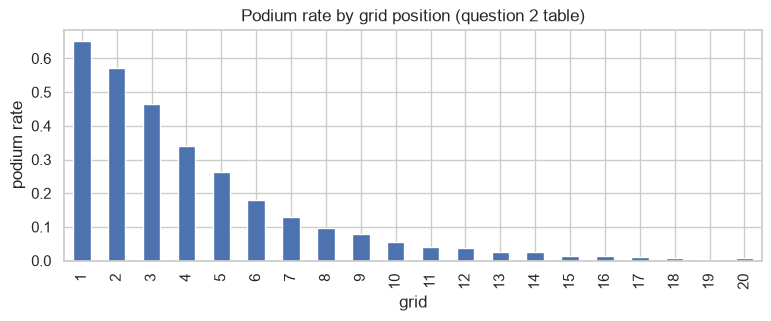

In [74]:
q2[q2['grid'] <= 20].groupby('grid')['podium'].mean().plot(kind='bar', figsize=(9, 3))
plt.title('Podium rate by grid position (question 2 table)')
plt.ylabel('podium rate')
plt.show()

The podium rate falls fast over the first rows and is close to zero after 10th. So the groups are narrow at the front and wide at the back: **1–3, 4–6, 7–10, 11+**.

In [75]:
q2['grid_bin'] = pd.cut(q2['grid'], bins=[0, 3, 6, 10, 40], labels=['1-3', '4-6', '7-10', '11+'])
q2['grid_bin'].value_counts().sort_index()

grid_bin
1-3      2975
4-6      2925
7-10     4004
11+     12271
Name: count, dtype: int64

In [76]:
by_bin = q2.groupby(['grid_bin', 'home'], observed=True).agg(starts=('podium', 'size'), podiums=('podium', 'sum'), rate=('podium', 'mean')).reset_index()
by_bin

,grid_bin,home,starts,podiums,rate
0,1-3,0,2747,1548,0.563524
1,1-3,1,228,131,0.574561
2,4-6,0,2701,704,0.260644
3,4-6,1,224,61,0.272321
4,7-10,0,3669,333,0.090760
5,7-10,1,335,25,0.074627
6,11+,0,11131,181,0.016261
7,11+,1,1140,13,0.011404


In [77]:
wide = by_bin.pivot(index='grid_bin', columns='home', values=['starts', 'rate'])
wide.columns = ['away_starts', 'home_starts', 'away_rate', 'home_rate']
wide['diff'] = wide['home_rate'] - wide['away_rate']
wide

,away_starts,home_starts,away_rate,home_rate,diff
grid_bin,,,,,
1-3,2747.0,228.0,0.563524,0.574561,0.011038
4-6,2701.0,224.0,0.260644,0.272321,0.011677
7-10,3669.0,335.0,0.090760,0.074627,-0.016134
11+,11131.0,1140.0,0.016261,0.011404,-0.004857


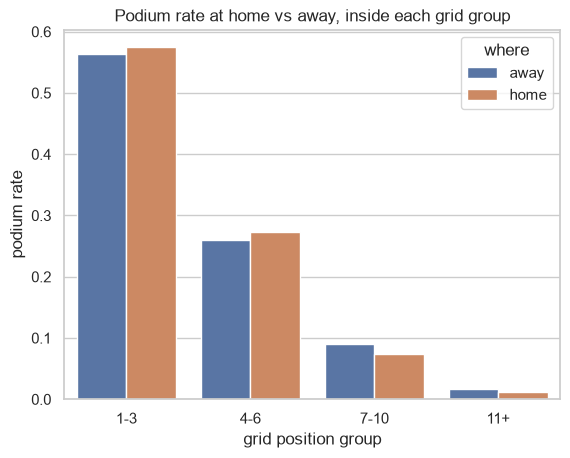

In [78]:
plot_bin = by_bin.copy()
plot_bin['where'] = plot_bin['home'].map({0: 'away', 1: 'home'})

sns.barplot(data=plot_bin, x='grid_bin', y='rate', hue='where')
plt.title('Podium rate at home vs away, inside each grid group')
plt.xlabel('grid position group')
plt.ylabel('podium rate')
plt.show()

### 2.5 One controlled number

**Method 1: weighted average of the differences.** We take the home-minus-away difference of each grid group and average them, weighted by the number of home starts in the group. In words: "for the grid positions that home drivers really had, how much higher is their podium rate than away drivers from the same positions?"

In [79]:
controlled_diff = (wide['diff'] * wide['home_starts']).sum() / wide['home_starts'].sum()
raw_diff = raw.loc[1, 'podium_rate'] - raw.loc[0, 'podium_rate']
raw_diff, controlled_diff

(np.float64(-0.01724957183749734), np.float64(-0.0030149969096303266))

The four groups are still wide (grid 1 and grid 3 are in the same group). As a check we repeat the same calculation with every single grid position as its own group.

In [80]:
by_pos = q2.groupby(['grid', 'home'])['podium'].agg(['size', 'mean']).unstack()
by_pos.columns = ['away_starts', 'home_starts', 'away_rate', 'home_rate']
by_pos = by_pos.dropna()
by_pos['diff'] = by_pos['home_rate'] - by_pos['away_rate']
by_pos.head(10)

,away_starts,home_starts,away_rate,home_rate,diff
grid,,,,,
1,937.0,80.0,0.656350,0.612500,-0.043850
2,914.0,75.0,0.573304,0.560000,-0.013304
3,896.0,73.0,0.456473,0.547945,0.091472
4,912.0,73.0,0.337719,0.369863,0.032144
5,899.0,70.0,0.256952,0.328571,0.071619
6,890.0,81.0,0.185393,0.135802,-0.049591
7,914.0,78.0,0.125821,0.153846,0.028026
8,905.0,77.0,0.098343,0.064935,-0.033407
9,918.0,94.0,0.079521,0.085106,0.005586


In [81]:
controlled_diff_exact = (by_pos['diff'] * by_pos['home_starts']).sum() / by_pos['home_starts'].sum()
controlled_diff_exact

np.float64(-0.0018477967982408092)

**Method 2: a simple logistic regression.** `podium ~ grid group + home`. The `home` coefficient says how the odds of a podium change at home for drivers in the same grid group. It also gives a confidence interval, which the weighted average does not.

In [82]:
model = smf.logit('podium ~ C(grid_bin) + home', data=q2).fit()
model.summary().tables[1]

Optimization terminated successfully.
         Current function value: 0.267015
         Iterations 8


,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,0.2620,0.038,6.970,0.000,0.188,0.336
C(grid_bin)[T.4-6],-1.2969,0.056,-23.154,0.000,-1.407,-1.187
C(grid_bin)[T.7-10],-2.5795,0.067,-38.735,0.000,-2.710,-2.449
C(grid_bin)[T.11+],-4.3895,0.081,-54.007,0.000,-4.549,-4.230
home,-0.0397,0.087,-0.454,0.650,-0.211,0.131


In [83]:
# odds ratio of home, with its 95% interval and p-value
np.exp(model.params['home']), np.exp(model.conf_int().loc['home']).tolist(), model.pvalues['home']

(np.float64(0.9611033517474779),
 [0.8099389176418867, 1.1404806370208986],
 np.float64(0.649541145272778))

### 2.6 Is it the same in old and modern F1?

The table mixes 75 years. One quick check: the same controlled difference for races before 1990 and from 1990.

In [84]:
q2['period'] = np.where(q2['year'] < 1990, '1950-1989', '1990-2024')
by_period = q2.groupby(['period', 'grid_bin', 'home'], observed=True)['podium'].agg(['size', 'mean']).unstack()
by_period.columns = ['away_starts', 'home_starts', 'away_rate', 'home_rate']
by_period['diff'] = by_period['home_rate'] - by_period['away_rate']
by_period

away_starts  home_starts  away_rate  home_rate      diff
period    grid_bin                                                          
1950-1989 1-3              1215          121   0.465021   0.545455  0.080434
          4-6              1171          133   0.292058   0.308271  0.016213
          7-10             1550          196   0.123871   0.107143 -0.016728
          11+              4927          759   0.022123   0.014493 -0.007630
1990-2024 1-3              1532          107   0.641645   0.607477 -0.034168
          4-6              1530           91   0.236601   0.219780 -0.016821
          7-10             2119          139   0.066541   0.028777 -0.037764
          11+              6204          381   0.011605   0.005249 -0.006356

In [85]:
by_period['weighted'] = by_period['diff'] * by_period['home_starts']
by_period.groupby('period')['weighted'].sum() / by_period.groupby('period')['home_starts'].sum()

period
1950-1989    0.002331
1990-2024   -0.017907
dtype: float64

### 2.7 Justification: grain, missingness, pre-race cutoff

**Grain.** One row is one driver starting one race, unique on (`raceId`, `driverId`). The join to `drivers` did not change the row count (checked above). The duplicate rule from section 0.7 matters here, because the shared drives of the 1950s are in this table: each driver counts once per race, with the best result.

**Missingness.**
- `grid = 0` is "no grid slot", not a position. We dropped the 1,701 entries that never started and the 87 starts with `grid = 0`, because they cannot be put in a grid group.
- No nationality is missing, and every nationality has a country in the mapping. 43 drivers (2,324 starts) come from a country that never held a race; they are left out because they can never be "at home".
- The 11 Indianapolis 500 races are left out: 99.7% of the entries were home drivers and only 4 of the 107 drivers ever raced elsewhere, so they are a separate population.
- "Home" follows `drivers.nationality`, one value per driver. Dual nationals get the first one, and `East German` drivers are matched to Germany. A driver's licence country can differ from where they grew up; the data does not have that.

**Pre-race cutoff.** `home`, the nationality, the circuit country and `grid` are all known before the race, so `home` is a legal feature. The podium is the outcome.

**What "controlling" means here.** We compare home and away drivers inside the same grid group. This removes the starting position, but not the car or the driver's skill. So the result is an association, not a cause.

### 2.8 Answer to question 2

**No. After controlling for starting position there is no home advantage in this data.**

The table has 22,175 race starts from 1950 to 2024 (Indianapolis 500 left out): 1,927 at home and 20,248 away.

- **Raw:** home drivers reach the podium *less* often, 11.9% (230 of 1,927) against 13.7% (2,766 of 20,248). But they also start further back (mean grid 12.7 against 11.8). So the opposite of the usual guess is true here: home drivers do not qualify better on average.
- **Inside grid groups** (home vs away):

| grid | home | away | difference |
|---|---|---|---|
| 1–3 | 57.5% (131/228) | 56.4% (1,548/2,747) | +1.1 points |
| 4–6 | 27.2% (61/224) | 26.1% (704/2,701) | +1.2 points |
| 7–10 | 7.5% (25/335) | 9.1% (333/3,669) | −1.6 points |
| 11+ | 1.1% (13/1,140) | 1.6% (181/11,131) | −0.5 points |

- **One controlled number:** the weighted average of these differences is **−0.3 percentage points**. With every grid position as its own group it is −0.2 points. The raw gap of −1.7 points almost disappears, so most of it came from the starting position.
- **Logistic regression** (`podium ~ grid group + home`): the odds ratio for home is **0.96**, with a 95% interval from 0.81 to 1.14 and p = 0.65. The interval contains 1, so the data does not show an effect in either direction.
- **By period:** +0.2 points in 1950–1989 and −1.8 points in 1990–2024. The sign is not stable and both are small.

The differences go both ways across the groups and are small next to the sample sizes (228 home starts in the front group). We conclude that a driver who starts from a similar grid position is about as likely to reach the podium at home as elsewhere. This is a comparison of groups, not proof that racing at home has no effect on a single driver: we did not control for the car or the driver.

---
## Question 3 – Which constructors have the highest mechanical-retirement rate in 2014–2021 vs. 2022–2024?

### Plan

- **Unit (grain):** one car starting one race (one row of `results` for a driver who started).
- **Mechanical-retirement rate of a constructor** = mechanical retirements / race starts, in each period.
- **Joins (multi-hop):** `results → races` (`raceId`) gives the year and so the period, `results → status` (`statusId`) gives the reason the race ended, `results → constructors` (`constructorId`) gives the team name.
- The assignment's definition: *a race start that ended early because a component of the car failed; not a crash, not the driver, not a regulation decision.* So we need (a) who started and (b) a class for every status.

### 3.1 Build the table for question 3

In [86]:
q3 = merged[merged['year'] >= 2014]
before = len(q3)
q3 = q3.merge(status, on='statusId').merge(constructors[['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId')
q3['period'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')
before, len(q3)

(4626, 4626)

In [87]:
q3.groupby('period').agg(races=('raceId', 'nunique'), rows=('raceId', 'size'), constructors=('constructor', 'nunique'))

,races,rows,constructors
period,,,
2014-2021,160,3267,19
2022-2024,68,1359,12


### 3.2 Every status value in 2014–2024

`status.csv` has 139 values but only some appear in these years. We list all of them with their counts, so every one can be classified by hand.

In [88]:
status_counts = q3['status'].value_counts()
len(status_counts)

66

In [89]:
status_counts.to_frame().T

status,Finished,+1 Lap,+2 Laps,Collision,Accident,Engine,Collision damage,Retired,Brakes,Power Unit,...,Drivetrain,Water pump,Out of fuel,Spark plugs,+5 Laps,Debris,Fuel system,Differential,Excluded,+7 Laps
count,2403,1178,208,150,85,81,59,50,49,42,...,1,1,1,1,1,1,1,1,1,1


### 3.3 Classify the statuses

The `+1 Lap`, `+2 Laps`, ... values mean the car was still running at the end, some laps behind the winner. Together with `Finished` they are class `finished`. All the others go in a plain dictionary.

Classes:

- `mechanical` – the status names a part or system of the car that failed.
- `accident` – crash, collision, or damage from one.
- `driver` – caused by the driver.
- `regulation` – decided by the stewards.
- `unclear` – the status does not say why the race ended.

In [90]:
status_class = {
    # a part or system of the car
    'Engine': 'mechanical', 'Power Unit': 'mechanical', 'ERS': 'mechanical', 'Turbo': 'mechanical',
    'Battery': 'mechanical', 'Power loss': 'mechanical', 'Spark plugs': 'mechanical', 'Exhaust': 'mechanical',
    'Gearbox': 'mechanical', 'Transmission': 'mechanical', 'Clutch': 'mechanical', 'Driveshaft': 'mechanical',
    'Drivetrain': 'mechanical', 'Differential': 'mechanical', 'Hydraulics': 'mechanical',
    'Electrical': 'mechanical', 'Electronics': 'mechanical', 'Throttle': 'mechanical',
    'Brakes': 'mechanical', 'Brake duct': 'mechanical', 'Suspension': 'mechanical', 'Steering': 'mechanical',
    'Wheel': 'mechanical', 'Wheel nut': 'mechanical', 'Vibrations': 'mechanical',
    'Oil leak': 'mechanical', 'Oil pressure': 'mechanical', 'Water leak': 'mechanical',
    'Water pressure': 'mechanical', 'Water pump': 'mechanical', 'Radiator': 'mechanical',
    'Overheating': 'mechanical', 'Cooling system': 'mechanical',
    'Fuel pressure': 'mechanical', 'Fuel leak': 'mechanical', 'Fuel system': 'mechanical',
    'Fuel pump': 'mechanical', 'Out of fuel': 'mechanical',
    'Front wing': 'mechanical', 'Rear wing': 'mechanical', 'Undertray': 'mechanical', 'Seat': 'mechanical',
    'Mechanical': 'mechanical', 'Technical': 'mechanical',
    # crash or damage
    'Collision': 'accident', 'Accident': 'accident', 'Collision damage': 'accident',
    'Damage': 'accident', 'Debris': 'accident',
    # the driver
    'Spun off': 'driver', 'Illness': 'driver',
    # the stewards
    'Disqualified': 'regulation', 'Excluded': 'regulation',
    # reason not given
    'Retired': 'unclear', 'Withdrew': 'unclear', 'Puncture': 'unclear', 'Tyre': 'unclear',
    'Finished': 'finished',
}
q3['status_class'] = q3['status'].map(status_class)
q3.loc[q3['status'].str.startswith('+'), 'status_class'] = 'finished'
q3['status_class'].isna().sum()

np.int64(0)

No status is left without a class. Here is the full list with class and count, so the reader can check each one.

In [91]:
check = q3.groupby(['status_class', 'status']).size().rename('rows').reset_index().sort_values(['status_class', 'rows'], ascending=[True, False])
pd.set_option('display.max_rows', 200)
check

,status_class,status,rows
1,accident,Collision,150
0,accident,Accident,85
2,accident,Collision damage,59
3,accident,Damage,2
4,accident,Debris,1
6,driver,Spun off,11
5,driver,Illness,3
15,finished,Finished,2403
7,finished,+1 Lap,1178
8,finished,+2 Laps,208


In [92]:
q3['status_class'].value_counts()

status_class
finished      3825
mechanical     403
accident       297
unclear         75
driver          14
regulation      12
Name: count, dtype: int64

**Borderline calls**

- `Power Unit`, `ERS`, `Turbo`, `Battery` are the hybrid-era names for engine parts → mechanical.
- `Wheel` and `Wheel nut` → mechanical. Often a wheel that was not fixed properly at a pit stop. It is a team error, but the car stopped because a part of it was not working, and it is not a crash, the driver, or a regulation decision.
- `Out of fuel` (1 row) → mechanical, for the same reason: the car could not go on, and none of the three exclusions applies.
- `Front wing`, `Rear wing`, `Undertray` (10 rows together) → mechanical because the status names a car part. Some of these may really be contact damage; the data has a separate `Collision damage` status for that, so we trust the label.
- `Collision damage`, `Damage`, `Debris` → accident. The part failed because of a crash or an object on track, which the definition excludes.
- `Spun off` → driver. `Illness` → driver.
- `Puncture` and `Tyre` (11 rows) → unclear. A tyre is a part of the car, but tyres mostly fail from debris, contact or wear, and the status does not say which. We do not count them.
- `Retired` and `Withdrew` → unclear. The team stopped the car and the reason is not recorded. We do not count them as mechanical, and we test below how much this choice matters.

### 3.4 Who started?

The denominator is race starts. From section 0.8, `positionText` = `W` (withdrawn) marks cars that did not start. We look at these rows before we drop them.

In [93]:
q3['positionText'].str.isdigit().map({True: 'classified (number)', False: 'letter'}).value_counts(), q3[~q3['positionText'].str.isdigit()]['positionText'].value_counts()

(positionText
 classified (number)    3905
 letter                  721
 Name: count, dtype: int64,
 positionText
 R    680
 W     28
 D     11
 N      1
 E      1
 Name: count, dtype: int64)

In [94]:
# the W rows: laps and status
not_started = q3[~q3['started']]
print(not_started['laps'].max())
not_started['status'].value_counts()

0


status
Withdrew       11
Power Unit      3
Gearbox         2
Engine          2
Fuel system     1
ERS             1
Exhaust         1
Driveshaft      1
Brakes          1
Illness         1
Power loss      1
Fuel leak       1
Hydraulics      1
Retired         1
Name: count, dtype: int64

All `W` rows have 0 laps. Many of them have a mechanical status (`Engine`, `Power Unit`, `Gearbox`): the car broke before the start. That is a failure, but not a *race start that ended early*, so by the assignment's definition these are out of both the numerator and the denominator.

In [95]:
q3 = q3[q3['started']]
len(q3)

4598

A related case: rows marked `R` (retired) with 0 laps and a mechanical status. The car stopped before it finished lap 1, or on the way to the grid.

In [96]:
q3[(q3['laps'] == 0) & (q3['status_class'] == 'mechanical')][['year', 'race_name', 'constructor', 'grid', 'positionText', 'status']]

,year,race_name,constructor,grid,positionText,status
3119,2015,Australian Grand Prix,Lotus F1,8,R,Power loss
4178,2022,Saudi Arabian Grand Prix,AlphaTauri,19,R,Power Unit
4226,2018,Italian Grand Prix,Toro Rosso,16,R,Brakes
4331,2017,British Grand Prix,Renault,11,R,Hydraulics
4385,2017,Bahrain Grand Prix,McLaren,17,R,Power Unit
4411,2017,Malaysian Grand Prix,Ferrari,0,R,Battery
4437,2022,Japanese Grand Prix,Williams,16,R,Hydraulics
4479,2023,Italian Grand Prix,AlphaTauri,11,R,Engine
4510,2018,Hungarian Grand Prix,Sauber,17,R,Suspension


The data marks these as retired, not withdrawn, and we cannot tell a failure on the formation lap from one in the first corners. We follow the data and keep them as starts. It is only a handful of rows, so it cannot change the ranking.

One more look: some mechanical statuses belong to a car that is classified with a number. A car is classified if it did 90% of the distance, even if it stopped before the flag. Its race still ended early because of a failure, so we count it.

In [97]:
q3['mech'] = (q3['status_class'] == 'mechanical').astype(int)
q3[q3['mech'] == 1]['positionText'].str.isdigit().value_counts()

positionText
False    348
True      40
Name: count, dtype: int64

In [98]:
q3.groupby('period')['mech'].agg(['size', 'sum', 'mean'])

,size,sum,mean
period,,,
2014-2021,3246,308,0.094886
2022-2024,1352,80,0.059172


### 3.5 Rate per constructor, with the names as given

First the simple version: group by the constructor name in the data.

In [99]:
by_name = q3.groupby(['period', 'constructor']).agg(starts=('mech', 'size'), mech=('mech', 'sum'), first=('year', 'min'), last=('year', 'max')).reset_index()
by_name['rate'] = by_name['mech'] / by_name['starts']
by_name.sort_values(['period', 'rate'], ascending=[True, False])

,period,constructor,starts,mech,first,last,rate
4,2014-2021,Caterham,33,7,2014,2014,0.212121
8,2014-2021,Lotus F1,75,14,2014,2015,0.186667
17,2014-2021,Toro Rosso,242,39,2014,2019,0.161157
15,2014-2021,Renault,199,29,2016,2020,0.145729
11,2014-2021,McLaren,316,43,2014,2021,0.136076
14,2014-2021,Red Bull,318,34,2014,2021,0.106918
16,2014-2021,Sauber,199,21,2014,2018,0.105528
10,2014-2021,Marussia,31,3,2014,2014,0.096774
7,2014-2021,Haas F1 Team,241,23,2016,2021,0.095436
1,2014-2021,AlphaTauri,77,7,2020,2021,0.090909


There is a problem for the comparison. Several teams changed their name, and each name is a different `constructorId`. `Toro Rosso`, `AlphaTauri` and `RB F1 Team` are the same team. So are `Force India`, `Racing Point` and `Aston Martin`, and others. With the names as given, `AlphaTauri` appears in both periods as two small pieces and `Force India` has no second period at all, so "2014–2021 vs 2022–2024" cannot be read for them.

### 3.6 Group the rebrands into team lineages

**Decision: compare by team lineage.** The same factory and mostly the same people build the car before and after a rename, and the question compares the same teams across two periods. The mapping is a plain dictionary:

- Toro Rosso → AlphaTauri → RB F1 Team
- Force India → Racing Point → Aston Martin
- Lotus F1 → Renault → Alpine F1 Team (the Enstone team; Renault bought Lotus F1 at the end of 2015)
- Sauber → Alfa Romeo → Sauber
- Marussia → Manor Marussia

One caveat: a lineage keeps the team but not always the engine supplier, so this is "the team", not "the engine".

In [100]:
lineage = {
    'Toro Rosso': 'Toro Rosso / AlphaTauri / RB',
    'AlphaTauri': 'Toro Rosso / AlphaTauri / RB',
    'RB F1 Team': 'Toro Rosso / AlphaTauri / RB',
    'Force India': 'Force India / Racing Point / Aston Martin',
    'Racing Point': 'Force India / Racing Point / Aston Martin',
    'Aston Martin': 'Force India / Racing Point / Aston Martin',
    'Lotus F1': 'Lotus F1 / Renault / Alpine',
    'Renault': 'Lotus F1 / Renault / Alpine',
    'Alpine F1 Team': 'Lotus F1 / Renault / Alpine',
    'Sauber': 'Sauber / Alfa Romeo',
    'Alfa Romeo': 'Sauber / Alfa Romeo',
    'Marussia': 'Marussia / Manor',
    'Manor Marussia': 'Marussia / Manor',
}
q3['team'] = q3['constructor'].replace(lineage)
q3.groupby('team')['constructor'].unique()

team
Caterham                                                                    [Caterham]
Ferrari                                                                      [Ferrari]
Force India / Racing Point / Aston Martin    [Racing Point, Aston Martin, Force India]
Haas F1 Team                                                            [Haas F1 Team]
Lotus F1 / Renault / Alpine                        [Alpine F1 Team, Renault, Lotus F1]
Marussia / Manor                                            [Marussia, Manor Marussia]
McLaren                                                                      [McLaren]
Mercedes                                                                    [Mercedes]
Red Bull                                                                    [Red Bull]
Sauber / Alfa Romeo                                               [Alfa Romeo, Sauber]
Toro Rosso / AlphaTauri / RB                      [AlphaTauri, Toro Rosso, RB F1 Team]
Williams                              

In [101]:
by_team = q3.groupby(['period', 'team']).agg(starts=('mech', 'size'), mech=('mech', 'sum')).reset_index()
by_team['rate'] = by_team['mech'] / by_team['starts']
by_team.sort_values('starts').head(5)

,period,team,starts,mech,rate
0,2014-2021,Caterham,33,7,0.212121
5,2014-2021,Marussia / Manor,108,7,0.064815
12,2022-2024,Ferrari,134,7,0.052239
13,2022-2024,Force India / Racing Point / Aston Martin,134,7,0.052239
21,2022-2024,Williams,134,8,0.059701


**Minimum: at least 50 starts in the period.** `Caterham` has only one season (2014) and falls under it. Every other team has more than 100 starts in each period it raced in. With fewer than 50 starts a single failure moves the rate by more than 2 points.

In [102]:
MIN_STARTS = 50
by_team_ok = by_team[by_team['starts'] >= MIN_STARTS]
by_team[by_team['starts'] < MIN_STARTS]

,period,team,starts,mech,rate
0,2014-2021,Caterham,33,7,0.212121


In [103]:
# ranking 2014-2021
rank_1 = by_team_ok[by_team_ok['period'] == '2014-2021'].sort_values('rate', ascending=False).reset_index(drop=True)
rank_1

,period,team,starts,mech,rate
0,2014-2021,Lotus F1 / Renault / Alpine,318,47,0.147799
1,2014-2021,Toro Rosso / AlphaTauri / RB,319,46,0.144201
2,2014-2021,McLaren,316,43,0.136076
3,2014-2021,Red Bull,318,34,0.106918
4,2014-2021,Haas F1 Team,241,23,0.095436
5,2014-2021,Sauber / Alfa Romeo,319,26,0.081505
6,2014-2021,Williams,319,24,0.075235
7,2014-2021,Marussia / Manor,108,7,0.064815
8,2014-2021,Force India / Racing Point / Aston Martin,317,20,0.063091
9,2014-2021,Ferrari,318,18,0.056604


In [104]:
# ranking 2022-2024
rank_2 = by_team_ok[by_team_ok['period'] == '2022-2024'].sort_values('rate', ascending=False).reset_index(drop=True)
rank_2

,period,team,starts,mech,rate
0,2022-2024,Lotus F1 / Renault / Alpine,135,14,0.103704
1,2022-2024,Sauber / Alfa Romeo,136,12,0.088235
2,2022-2024,Toro Rosso / AlphaTauri / RB,136,9,0.066176
3,2022-2024,Williams,134,8,0.059701
4,2022-2024,Force India / Racing Point / Aston Martin,134,7,0.052239
5,2022-2024,Ferrari,134,7,0.052239
6,2022-2024,Haas F1 Team,135,7,0.051852
7,2022-2024,Mercedes,136,6,0.044118
8,2022-2024,McLaren,136,5,0.036765
9,2022-2024,Red Bull,136,5,0.036765


In [105]:
team_wide = by_team_ok.pivot(index='team', columns='period', values='rate')
team_wide['change'] = team_wide['2022-2024'] - team_wide['2014-2021']
team_wide.sort_values('2014-2021', ascending=False).round(3)

period,2014-2021,2022-2024,change
team,,,
Lotus F1 / Renault / Alpine,0.148,0.104,-0.044
Toro Rosso / AlphaTauri / RB,0.144,0.066,-0.078
McLaren,0.136,0.037,-0.099
Red Bull,0.107,0.037,-0.070
Haas F1 Team,0.095,0.052,-0.044
Sauber / Alfa Romeo,0.082,0.088,0.007
Williams,0.075,0.060,-0.016
Marussia / Manor,0.065,NaN,NaN
Force India / Racing Point / Aston Martin,0.063,0.052,-0.011


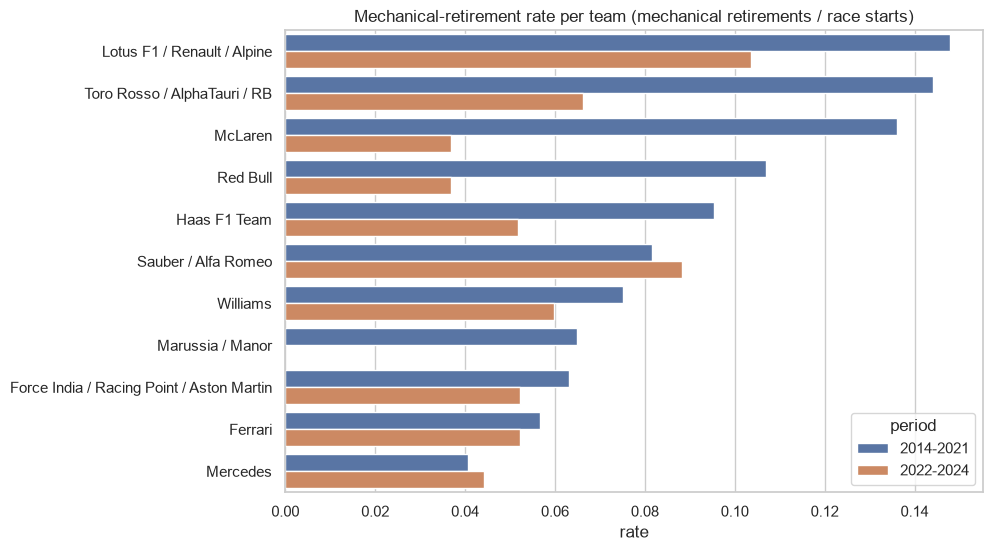

In [106]:
plt.figure(figsize=(9, 6))
sns.barplot(data=by_team_ok, y='team', x='rate', hue='period', order=rank_1['team'])
plt.title('Mechanical-retirement rate per team (mechanical retirements / race starts)')
plt.xlabel('rate')
plt.ylabel('')
plt.show()

The bars are sorted by the 2014–2021 rate. `Marussia / Manor` has no second bar because the team stopped after 2016.

### 3.7 What ended the races in each period?

A second view to put the mechanical rate in context: the share of starts in each status class, per period.

In [107]:
mix = pd.crosstab(q3['period'], q3['status_class'], normalize='index')
mix.round(3)

status_class,accident,driver,finished,mechanical,regulation,unclear
period,,,,,,
2014-2021,0.066,0.002,0.819,0.095,0.002,0.015
2022-2024,0.062,0.004,0.862,0.059,0.003,0.010


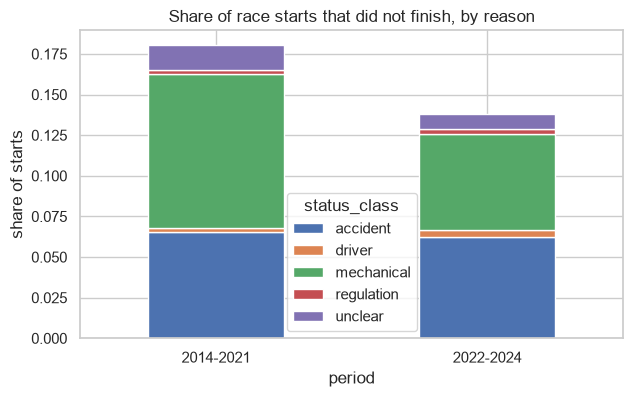

In [108]:
mix.drop(columns='finished').plot(kind='bar', stacked=True, figsize=(7, 4))
plt.title('Share of race starts that did not finish, by reason')
plt.ylabel('share of starts')
plt.xticks(rotation=0)
plt.show()

### 3.8 Does the answer depend on the unclear statuses?

We did not count `Retired`, `Withdrew`, `Puncture` and `Tyre`. Here we count them all as mechanical (the widest possible definition) and see if the ranking changes.

In [109]:
q3['mech_wide'] = q3['status_class'].isin(['mechanical', 'unclear']).astype(int)
wide_team = q3.groupby(['period', 'team']).agg(starts=('mech', 'size'), rate=('mech', 'mean'), rate_wide=('mech_wide', 'mean')).reset_index()
wide_team = wide_team[wide_team['starts'] >= MIN_STARTS]
wide_team.sort_values(['period', 'rate_wide'], ascending=[True, False]).round(3)

,period,team,starts,rate,rate_wide
4,2014-2021,Lotus F1 / Renault / Alpine,318,0.148,0.167
10,2014-2021,Toro Rosso / AlphaTauri / RB,319,0.144,0.163
6,2014-2021,McLaren,316,0.136,0.155
3,2014-2021,Haas F1 Team,241,0.095,0.124
8,2014-2021,Red Bull,318,0.107,0.116
9,2014-2021,Sauber / Alfa Romeo,319,0.082,0.097
11,2014-2021,Williams,319,0.075,0.094
5,2014-2021,Marussia / Manor,108,0.065,0.083
2,2014-2021,Force India / Racing Point / Aston Martin,317,0.063,0.069
1,2014-2021,Ferrari,318,0.057,0.063


### 3.9 Justification: grain, missingness, pre-race cutoff

**Grain.** One row is one car that started one race (one driver of one constructor in one race). The table is unique on (`raceId`, `driverId`), and the joins to `status` and `constructors` did not change the row count. The rate is counted per period and per team, with race starts as the denominator.

**Missingness.**
- `statusId` is never missing and all 66 status values that appear in 2014–2024 have a class (checked above).
- The real gap is in the meaning: `Retired` and `Withdrew` (and tyre problems) do not say why the car stopped. That is 75 rows, against 388 mechanical ones. We do not count them, and section 3.8 shows the top of the ranking is the same if we do.
- 28 entries that never started (`W`) are out of the rate, also when the reason was mechanical.
- `Caterham` (33 starts, one season) is under the minimum of 50 starts and is not ranked. Its rate would be the highest of all (21.2%, 7 of 33).
- `Marussia / Manor` has no rate for 2022–2024 because the team no longer existed.

**Pre-race cutoff.** `status` is written after the race, so the status of the race being predicted can never be a feature. This section only describes past races. A reliability feature for the model (for example the team's mechanical-retirement rate in its last 10 races) must use earlier races only.

### 3.10 Answer to question 3

**Overall.** Cars became more reliable: 9.5% of race starts ended with a mechanical retirement in 2014–2021 (308 of 3,246) and 5.9% in 2022–2024 (80 of 1,352).

**By team lineage (rebrands grouped, at least 50 starts in the period).**

| rank | 2014–2021 | rate | 2022–2024 | rate |
|---|---|---|---|---|
| 1 | Lotus F1 / Renault / Alpine | 14.8% (47/318) | Lotus F1 / Renault / Alpine | 10.4% (14/135) |
| 2 | Toro Rosso / AlphaTauri / RB | 14.4% (46/319) | Sauber / Alfa Romeo | 8.8% (12/136) |
| 3 | McLaren | 13.6% (43/316) | Toro Rosso / AlphaTauri / RB | 6.6% (9/136) |
| 4 | Red Bull | 10.7% (34/318) | Williams | 6.0% (8/134) |
| 5 | Haas | 9.5% (23/241) | Aston Martin lineage, Ferrari, Haas | 5.2% (7 each) |
| last | Mercedes | 4.1% (13/320) | McLaren and Red Bull | 3.7% (5/136 each) |

- The Enstone team (Lotus F1 / Renault / Alpine) has the highest rate in **both** periods.
- The biggest change is at McLaren and Red Bull: 3rd and 4th worst in 2014–2021 (the Honda and Renault power-unit years), the two most reliable in 2022–2024.
- Sauber / Alfa Romeo is the only midfield team that got slightly worse (8.2% → 8.8%) and moved up to 2nd. Mercedes is about the same (4.1% → 4.4%) and is no longer the most reliable.

**With the constructor names as given in the data** (same minimum of 50 starts) the top is: 2014–2021 Lotus F1 18.7% (14/75), Toro Rosso 16.1% (39/242), Renault 14.6% (29/199), McLaren 13.6%; 2022–2024 Alfa Romeo 12.5% (11/88), Alpine 10.4% (14/135), AlphaTauri 8.0% (7/88). The picture is the same, but the names are cut into short pieces, which is why we prefer the lineage table.

**How sure are we?** In 2022–2024 each team has only about 135 starts and 5 to 14 mechanical retirements, so teams one or two retirements apart are not really different. The clear results are the top (Alpine lineage) and the bottom (McLaren, Red Bull) of each list, and the overall drop. The result also depends on the status labels in the data: counting `Retired`, `Withdrew` and tyre problems as mechanical raises every rate a little but keeps the same team on top in both periods.